# Clustering de patrones históricos del mercado Brent

## Cuarta preentrega de aprendizaje no supervisado

Este análisis estudia si las condiciones mensuales del mercado petrolero pueden organizarse en grupos con características diferenciadas a partir del precio del Brent, sus variaciones recientes, el riesgo geopolítico y el balance mundial de petróleo.

La pregunta que guía el notebook es: **¿es posible identificar patrones históricos del mercado petrolero utilizando información del Brent y del riesgo geopolítico?** Los grupos se obtienen sin etiquetas previas y se interpretan después del ajuste. Por lo tanto, el análisis es descriptivo: no busca predecir el mes siguiente ni establecer relaciones causales.

## 1. Datos y alcance del análisis

El dataset mensual integrado reúne el precio spot del Brent, los índices GPR, GPRT y GPRA, y variables mundiales de producción y consumo. Contiene 336 observaciones consecutivas entre enero de 1998 y diciembre de 2025.

La unidad de análisis es el mes. Cada observación representa las condiciones conocidas al cierre de ese período. Las columnas referidas al mes siguiente se conservan en el archivo para los experimentos supervisados, pero se excluyen expresamente del clustering.

## 2. Librerías y configuración

Se utilizan herramientas de pandas y NumPy para la preparación de datos, Matplotlib para las visualizaciones y scikit-learn para la estandarización, K-Means, PCA y las métricas de evaluación interna. Se fija una semilla para asegurar la reproducibilidad.

In [1]:
import os
os.environ.setdefault("LOKY_MAX_CPU_COUNT", "4")

from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, davies_bouldin_score, silhouette_score
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_columns", 30)

RANDOM_STATE = 42
K_VALUES = range(2, 9)
COLORS = ["#4C78A8", "#F58518", "#54A24B"]

ROOT = Path.cwd()
if not (ROOT / "data" / "processed").exists():
    ROOT = ROOT.parent
DATA_FILE = ROOT / "data" / "processed" / "brent_gpr_market_monthly.csv"

## 3. Carga y controles temporales

Antes de construir las variables se verifica que las fechas estén ordenadas, que no existan meses duplicados y que la serie mensual sea continua. Estos controles evitan que los retornos y las ventanas móviles se calculen sobre observaciones desalineadas.

In [2]:
df = pd.read_csv(DATA_FILE, parse_dates=["month"]).sort_values("month").reset_index(drop=True)

expected_months = pd.Series(
    pd.date_range(df["month"].min(), df["month"].max(), freq="MS"),
    name="month",
)
assert df["month"].is_monotonic_increasing
assert df["month"].is_unique
assert df["month"].equals(expected_months)

print("Dimensión original:", df.shape)
print("Período:", df["month"].min().date(), "a", df["month"].max().date())
display(df.head(3))

Dimensión original: (336, 13)
Período: 1998-01-01 a 2025-12-01


,month,brent_price,GPR,GPRT,GPRA,world_production,world_consumption,world_crude_production,world_market_balance,brent_price_next_month,brent_return_next_month,brent_up_next_month,data_status
0,1998-01-01,15.19,53.096302,59.821270,42.487816,76.49,73.08,66.56,3.41,14.07,-0.073733,0.0,historical_revised_STEO_vintage_2026_09
1,1998-02-01,14.07,77.597618,101.840828,45.368019,76.90,74.50,66.93,2.40,13.10,-0.068941,0.0,historical_revised_STEO_vintage_2026_09
2,1998-03-01,13.10,57.248062,65.501999,44.516712,76.71,74.30,66.81,2.41,13.53,0.032824,1.0,historical_revised_STEO_vintage_2026_09


## 4. Construcción y selección de características

Las variables se eligen para representar dimensiones económicas distintas sin incorporar información futura:

| Variable | Dimensión representada | Tratamiento |
|---|---|---|
| `brent_price` | Nivel mensual del precio del Brent. | Valor contemporáneo, en USD por barril. |
| `brent_return_pct` | Dirección e intensidad del movimiento mensual. | Variación porcentual respecto del mes anterior. |
| `brent_volatility_6m` | Inestabilidad reciente del precio. | Desvío estándar de los últimos seis retornos, incluido el mes actual. |
| `log_GPR` | Intensidad del riesgo geopolítico. | `log1p(GPR)` para reducir su marcada asimetría. |
| `world_market_balance` | Situación agregada de oferta y demanda. | Producción mundial menos consumo mundial, en millones de barriles diarios. |

GPRT y GPRA no se incorporan junto con GPR porque contienen información altamente redundante. Del mismo modo, producción, consumo y producción de crudo no se utilizan simultáneamente: comparten una tendencia de largo plazo y podrían dar un peso excesivo a una misma dimensión. El balance mundial resume de forma más directa la diferencia entre oferta y demanda.

In [3]:
df["brent_return_pct"] = df["brent_price"].pct_change(fill_method=None) * 100
df["brent_volatility_6m"] = df["brent_return_pct"].rolling(6).std()
for column in ["GPR", "GPRT", "GPRA"]:
    df[f"log_{column}"] = np.log1p(df[column])

FEATURES_INITIAL = [
    "brent_price", "brent_return_pct", "brent_volatility_6m",
    "GPR", "world_market_balance",
]
FEATURES_FINAL = [
    "brent_price", "brent_return_pct", "brent_volatility_6m",
    "log_GPR", "world_market_balance",
]
FUTURE_COLUMNS = [
    "brent_price_next_month", "brent_return_next_month", "brent_up_next_month",
]

assert not set(FEATURES_FINAL).intersection(FUTURE_COLUMNS)
assert np.allclose(
    df["brent_return_pct"].dropna(),
    100 * df["brent_price"].pct_change(fill_method=None).dropna(),
)

missing = df[FEATURES_FINAL].isna().sum().rename("faltantes").to_frame()
display(missing)
print("Las seis filas iniciales sin volatilidad histórica se excluyen después del diagnóstico.")

,faltantes
brent_price,0
brent_return_pct,1
brent_volatility_6m,6
log_GPR,0
world_market_balance,0


Las seis filas iniciales sin volatilidad histórica se excluyen después del diagnóstico.


## 5. Exploración de las variables seleccionadas

K-Means agrupa observaciones según distancias euclidianas, por lo que resulta necesario revisar faltantes, valores extremos, asimetría y correlaciones. Los outliers no se eliminan, ya que corresponden a episodios económicos reales; en cambio, GPR se transforma logarítmicamente para limitar la influencia desproporcionada de sus picos más altos.

In [4]:
def iqr_diagnostics(frame, columns):
    rows = []
    for column in columns:
        series = frame[column].dropna()
        q1, q3 = series.quantile([0.25, 0.75])
        iqr = q3 - q1
        lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        rows.append({
            "variable": column,
            "asimetría": series.skew(),
            "límite_IQR_inferior": lower,
            "límite_IQR_superior": upper,
            "n_fuera_IQR": int(((series < lower) | (series > upper)).sum()),
        })
    return pd.DataFrame(rows).set_index("variable")

outlier_table = iqr_diagnostics(
    df,
    ["brent_price", "brent_return_pct", "brent_volatility_6m", "GPR", "log_GPR", "world_market_balance"],
)
display(outlier_table.round(3))

print(f"Asimetría de GPR: {df['GPR'].skew():.3f}")
print(f"Asimetría de log1p(GPR): {df['log_GPR'].skew():.3f}")

,asimetría,límite_IQR_inferior,límite_IQR_superior,n_fuera_IQR
variable,,,,
brent_price,0.173,-28.170,148.710,0
brent_return_pct,0.036,-22.783,25.085,8
brent_volatility_6m,3.501,-0.600,16.241,14
GPR,4.061,21.208,176.395,13
log_GPR,1.039,3.796,5.371,10
world_market_balance,2.287,-5.019,4.371,5


Asimetría de GPR: 4.061
Asimetría de log1p(GPR): 1.039


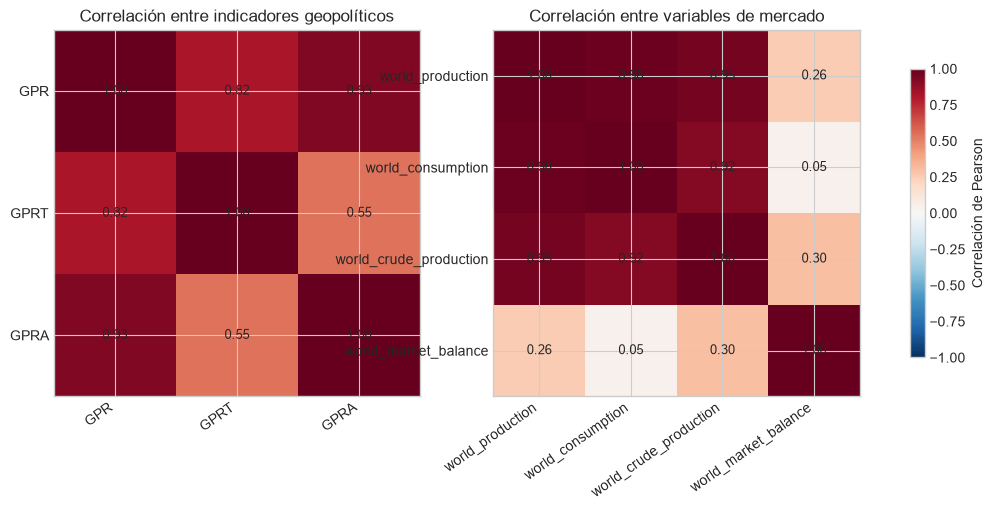

,GPR,GPRT,GPRA
GPR,1.000,0.820,0.926
GPRT,0.820,1.000,0.546
GPRA,0.926,0.546,1.000


,world_production,world_consumption,world_crude_production,world_market_balance
world_production,1.000,0.977,0.953,0.256
world_consumption,0.977,1.000,0.919,0.046
world_crude_production,0.953,0.919,1.000,0.302
world_market_balance,0.256,0.046,0.302,1.000


In [5]:
gpr_corr = df[["GPR", "GPRT", "GPRA"]].corr()
market_corr = df[[
    "world_production", "world_consumption", "world_crude_production", "world_market_balance"
]].corr()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, matrix, title in [
    (axes[0], gpr_corr, "Correlación entre indicadores geopolíticos"),
    (axes[1], market_corr, "Correlación entre variables de mercado"),
]:
    image = ax.imshow(matrix, vmin=-1, vmax=1, cmap="RdBu_r")
    ax.set_xticks(range(len(matrix.columns)), matrix.columns, rotation=35, ha="right")
    ax.set_yticks(range(len(matrix.index)), matrix.index)
    ax.set_title(title)
    for i in range(len(matrix.index)):
        for j in range(len(matrix.columns)):
            ax.text(j, i, f"{matrix.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9)
fig.colorbar(image, ax=axes, shrink=0.75, label="Correlación de Pearson")
plt.show()

display(gpr_corr.round(3))
display(market_corr.round(3))

La transformación reduce la asimetría de GPR de 4,061 a 1,039 sin eliminar observaciones. Las correlaciones de GPR con GPRT y GPRA son 0,820 y 0,926, respectivamente, lo que respalda el uso de un único indicador geopolítico. Producción y consumo mundial presentan una correlación de 0,977; por ello se conserva el balance, cuya relación con los niveles individuales es considerablemente menor.

Los valores extremos permanecen en la muestra y se consideran al interpretar la estabilidad y el tamaño de los grupos.

## 6. Preparación y estandarización

La volatilidad de seis meses no está disponible para las seis primeras observaciones. Esos meses se excluyen y la muestra de clustering queda conformada por 330 observaciones entre julio de 1998 y diciembre de 2025.

Las cinco características se estandarizan mediante `StandardScaler`. De este modo, cada variable aporta en función de sus desviaciones respecto de la media y no de su unidad de medida. Como el objetivo es describir la historia completa y no evaluar predicciones fuera de muestra, el escalador se ajusta sobre toda la muestra analizada.

In [6]:
analysis = df.dropna(subset=FEATURES_FINAL).copy().reset_index(drop=True)

assert len(analysis) == 330
assert analysis["month"].min() == pd.Timestamp("1998-07-01")
assert analysis["month"].max() == pd.Timestamp("2025-12-01")
assert not analysis[FEATURES_FINAL].isna().any().any()

print("Muestra de clustering:", len(analysis), "meses")
print("Período analizado:", analysis["month"].min().date(), "a", analysis["month"].max().date())

Muestra de clustering: 330 meses
Período analizado: 1998-07-01 a 2025-12-01


## 7. Implementación inicial y análisis de sensibilidad

La configuración inicial utiliza GPR sin transformar. Luego se evalúa la versión con `log1p(GPR)` y dos alternativas de selección de variables: excluir el nivel de precio e incorporar simultáneamente los componentes geopolíticos.

Para cada configuración se ajusta K-Means con inicialización `k-means++`, 50 inicializaciones, un máximo de 300 iteraciones y la misma semilla. Se comparan valores de K entre 2 y 8 mediante inercia, silhouette, Davies-Bouldin y tamaño de los grupos.

In [7]:
def evaluate_configuration(frame, features, name, k_values=K_VALUES):
    scaler = StandardScaler()
    scaled = scaler.fit_transform(frame[features])
    rows = []
    for k in k_values:
        model = KMeans(
            n_clusters=k,
            init="k-means++",
            n_init=50,
            max_iter=300,
            random_state=RANDOM_STATE,
        )
        labels = model.fit_predict(scaled)
        counts = pd.Series(labels).value_counts()
        rows.append({
            "configuración": name,
            "K": k,
            "inercia": model.inertia_,
            "silhouette": silhouette_score(scaled, labels),
            "davies_bouldin": davies_bouldin_score(scaled, labels),
            "grupo_mínimo": int(counts.min()),
            "grupo_máximo": int(counts.max()),
        })
    return pd.DataFrame(rows)

FEATURES_NO_PRICE = [
    "brent_return_pct", "brent_volatility_6m", "log_GPR", "world_market_balance",
]
FEATURES_REDUNDANT = [
    "brent_price", "brent_return_pct", "brent_volatility_6m",
    "log_GPR", "log_GPRT", "log_GPRA", "world_market_balance",
]

evaluations = pd.concat([
    evaluate_configuration(analysis, FEATURES_INITIAL, "Inicial: GPR sin transformar"),
    evaluate_configuration(analysis, FEATURES_FINAL, "Final: log1p(GPR)"),
    evaluate_configuration(analysis, FEATURES_NO_PRICE, "Sensibilidad: sin precio"),
    evaluate_configuration(analysis, FEATURES_REDUNDANT, "Sensibilidad: GPR + componentes"),
], ignore_index=True)

best_by_silhouette = evaluations.loc[
    evaluations.groupby("configuración")["silhouette"].idxmax()
].sort_values("silhouette", ascending=False)
display(best_by_silhouette.round(3))

,configuración,K,inercia,silhouette,davies_bouldin,grupo_mínimo,grupo_máximo
15,Sensibilidad: sin precio,3,876.062,0.241,1.306,6,196
10,Final: log1p(GPR),5,859.297,0.234,1.242,5,133
27,Sensibilidad: GPR + componentes,8,879.463,0.229,1.189,2,103
3,Inicial: GPR sin transformar,5,833.467,0.227,1.160,6,128


Las mejores puntuaciones de silhouette no implican necesariamente una solución adecuada. La configuración sin precio alcanza 0,241 con K=3, pero genera un grupo de solo seis meses. La versión con componentes geopolíticos redundantes produce un grupo de dos observaciones. Estas particiones reflejan casos extremos más que patrones suficientemente representativos.

La transformación logarítmica se conserva por su fundamento estadístico y no porque maximice la métrica. También se mantiene el nivel de precio, ya que forma parte de la pregunta económica y permite distinguir condiciones históricas con niveles diferentes del Brent.

## 8. Evaluación y selección de la configuración final

El número de clústeres se determina combinando cuatro criterios:

1. reducción de la inercia;
2. silhouette, donde valores mayores indican mejor cohesión y separación;
3. Davies-Bouldin, donde valores menores son preferibles;
4. tamaño e interpretabilidad de los grupos.

Ninguna métrica se utiliza de manera aislada.

,K,inercia,silhouette,davies_bouldin,grupo_mínimo,grupo_máximo
0,2,1354.075,0.208,1.877,146,184
1,3,1144.771,0.201,1.601,78,138
2,4,988.593,0.197,1.370,6,119
3,5,859.297,0.234,1.242,5,133
4,6,751.488,0.225,1.162,2,101
5,7,674.166,0.222,1.141,2,84
6,8,614.118,0.221,1.105,2,71


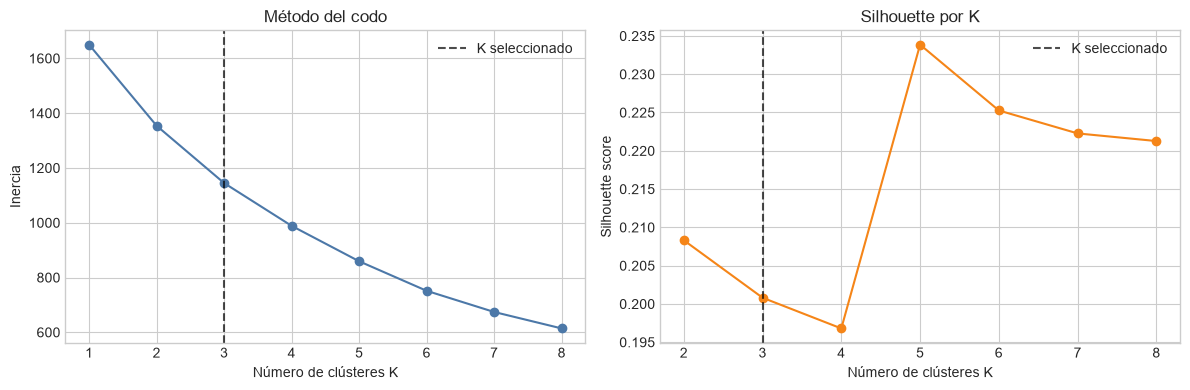

In [8]:
final_evaluation = (
    evaluations.query("configuración == 'Final: log1p(GPR)'")
    .drop(columns="configuración")
    .reset_index(drop=True)
)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(analysis[FEATURES_FINAL])
inertias = []
for k in range(1, 9):
    model = KMeans(
        n_clusters=k, init="k-means++", n_init=50, max_iter=300,
        random_state=RANDOM_STATE,
    ).fit(X_scaled)
    inertias.append(model.inertia_)

display(final_evaluation.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(range(1, 9), inertias, marker="o", color="#4C78A8")
axes[0].axvline(3, color="black", linestyle="--", alpha=0.7, label="K seleccionado")
axes[0].set(title="Método del codo", xlabel="Número de clústeres K", ylabel="Inercia")
axes[0].legend()

axes[1].plot(final_evaluation["K"], final_evaluation["silhouette"], marker="o", color="#F58518")
axes[1].axvline(3, color="black", linestyle="--", alpha=0.7, label="K seleccionado")
axes[1].set(title="Silhouette por K", xlabel="Número de clústeres K", ylabel="Silhouette score")
axes[1].legend()
plt.tight_layout()
plt.show()

### Configuración seleccionada

K=5 obtiene el silhouette más alto, 0,234, pero crea un grupo de apenas cinco meses, concentrado en movimientos extraordinarios de 2020. K=2 produce grupos equilibrados y un silhouette de 0,208, aunque presenta un Davies-Bouldin más alto y resume en exceso condiciones económicas diferentes.

Se selecciona **K=3** como compromiso entre separación, representatividad e interpretación. Esta solución alcanza un silhouette de 0,201, un Davies-Bouldin de 1,601 y grupos de 78, 114 y 138 meses. La ausencia de un codo marcado y el nivel bajo de silhouette indican que los grupos deben entenderse como perfiles aproximados, no como regímenes perfectamente delimitados.

## 9. Ajuste final y estabilidad

El modelo final conserva los hiperparámetros evaluados y se ajusta sobre las cinco variables estandarizadas. Debido a que los números asignados por K-Means son arbitrarios, las etiquetas se reordenan según el nivel de precio del centroide: el Grupo 0 presenta el menor precio medio y el Grupo 2 el mayor.

Además, se repite el ajuste con cinco semillas para comprobar si la partición depende de la inicialización.

In [9]:
FINAL_K = 3
final_model = KMeans(
    n_clusters=FINAL_K,
    init="k-means++",
    n_init=50,
    max_iter=300,
    random_state=RANDOM_STATE,
)
raw_labels = final_model.fit_predict(X_scaled)

price_position = FEATURES_FINAL.index("brent_price")
ordered_raw_labels = np.argsort(final_model.cluster_centers_[:, price_position])
label_map = {raw_label: ordered_label for ordered_label, raw_label in enumerate(ordered_raw_labels)}
labels = np.array([label_map[label] for label in raw_labels])
centers_scaled = final_model.cluster_centers_[ordered_raw_labels]

clustered = analysis.copy()
clustered["cluster"] = labels

counts = clustered["cluster"].value_counts().sort_index()
final_silhouette = silhouette_score(X_scaled, labels)
final_davies_bouldin = davies_bouldin_score(X_scaled, labels)

print("Silhouette final:", round(final_silhouette, 4))
print("Davies-Bouldin final:", round(final_davies_bouldin, 4))
display(counts.rename("meses").to_frame())

Silhouette final: 0.2008
Davies-Bouldin final: 1.6012


,meses
cluster,
0,78
1,114
2,138


In [10]:
seed_rows = []
for seed in [0, 7, 21, 42, 99]:
    candidate = KMeans(
        n_clusters=FINAL_K, init="k-means++", n_init=50, max_iter=300,
        random_state=seed,
    ).fit_predict(X_scaled)
    seed_rows.append({
        "random_state": seed,
        "ARI_vs_seed_42": adjusted_rand_score(raw_labels, candidate),
    })

seed_stability = pd.DataFrame(seed_rows)
display(seed_stability.round(3))
print("ARI=1 implica la misma partición, aunque los números de etiqueta puedan permutarse.")

,random_state,ARI_vs_seed_42
0,0,1.0
1,7,1.0
2,21,1.0
3,42,1.0
4,99,1.0


ARI=1 implica la misma partición, aunque los números de etiqueta puedan permutarse.


## 10. Visualización y caracterización de los grupos

### Proyección mediante PCA

PCA reduce las cinco variables estandarizadas a dos componentes para facilitar la representación gráfica. El modelo no se ajusta sobre esta proyección: las etiquetas proceden del espacio original de cinco dimensiones.

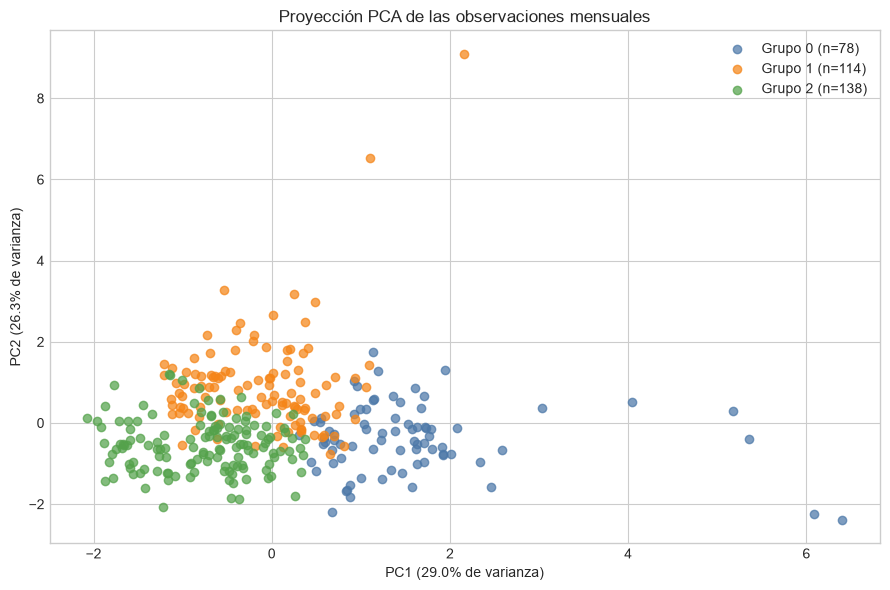

Varianza explicada acumulada en dos componentes: 0.5524


,brent_price,brent_return_pct,brent_volatility_6m,log_GPR,world_market_balance
PC1,-0.619,0.245,0.707,-0.238,0.017
PC2,-0.194,-0.651,0.106,0.201,0.698


In [11]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
pca_frame = pd.DataFrame(X_pca, columns=["PC1", "PC2"])
pca_frame["cluster"] = labels

fig, ax = plt.subplots(figsize=(9, 6))
for cluster_id, color in enumerate(COLORS):
    subset = pca_frame[pca_frame["cluster"] == cluster_id]
    ax.scatter(
        subset["PC1"], subset["PC2"], s=36, alpha=0.72,
        label=f"Grupo {cluster_id} (n={len(subset)})", color=color,
    )
ax.set(
    title="Proyección PCA de las observaciones mensuales",
    xlabel=f"PC1 ({pca.explained_variance_ratio_[0]:.1%} de varianza)",
    ylabel=f"PC2 ({pca.explained_variance_ratio_[1]:.1%} de varianza)",
)
ax.legend()
plt.tight_layout()
plt.show()

print("Varianza explicada acumulada en dos componentes:", round(pca.explained_variance_ratio_.sum(), 4))
loadings = pd.DataFrame(pca.components_, columns=FEATURES_FINAL, index=["PC1", "PC2"])
display(loadings.round(3))

Los dos primeros componentes explican en conjunto el 55,24% de la varianza. La superposición visible entre grupos coincide con el silhouette bajo y confirma que la estructura encontrada es gradual. Por ello, la distancia aparente en el gráfico no debe interpretarse como una separación completa del espacio original.

### Perfil de los centroides

Las medias siguientes se expresan en las unidades originales. Aunque el modelo utiliza `log_GPR`, el perfil muestra GPR en su escala original para facilitar su lectura.

,meses,% muestra,Brent USD/barril,retorno mensual %,volatilidad 6m %,GPR,balance mundial
cluster,,,,,,,
0,78,23.64,35.72,6.39,13.31,78.33,-0.72
1,114,34.55,53.55,-4.37,8.23,141.26,0.69
2,138,41.82,88.63,2.42,5.95,92.87,-0.77


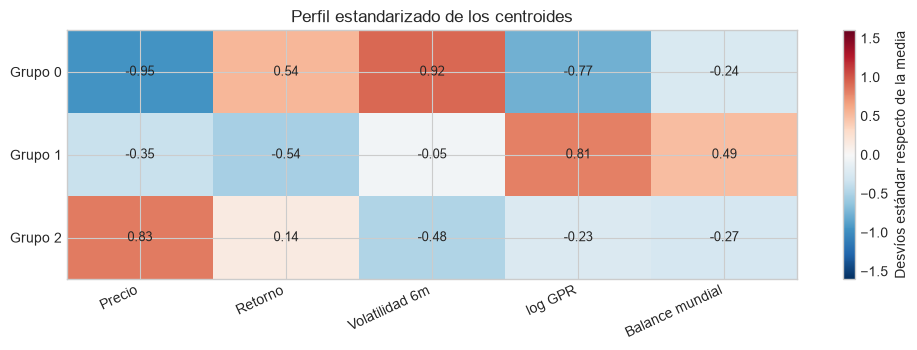

In [12]:
profile_columns = [
    "brent_price", "brent_return_pct", "brent_volatility_6m", "GPR", "world_market_balance",
]
profiles = clustered.groupby("cluster")[profile_columns].mean()
profiles["meses"] = clustered.groupby("cluster").size()
profiles["porcentaje"] = 100 * profiles["meses"] / len(clustered)
profiles = profiles[["meses", "porcentaje"] + profile_columns]
profiles.columns = [
    "meses", "% muestra", "Brent USD/barril", "retorno mensual %",
    "volatilidad 6m %", "GPR", "balance mundial",
]
display(profiles.round(2))

centroid_profile = pd.DataFrame(
    centers_scaled,
    index=[f"Grupo {i}" for i in range(FINAL_K)],
    columns=["Precio", "Retorno", "Volatilidad 6m", "log GPR", "Balance mundial"],
)

fig, ax = plt.subplots(figsize=(10, 3.6))
image = ax.imshow(centroid_profile, cmap="RdBu_r", vmin=-1.6, vmax=1.6, aspect="auto")
ax.set_xticks(range(len(centroid_profile.columns)), centroid_profile.columns, rotation=25, ha="right")
ax.set_yticks(range(FINAL_K), centroid_profile.index)
ax.set_title("Perfil estandarizado de los centroides")
for i in range(FINAL_K):
    for j in range(len(centroid_profile.columns)):
        ax.text(j, i, f"{centroid_profile.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9)
fig.colorbar(image, ax=ax, label="Desvíos estándar respecto de la media")
plt.tight_layout()
plt.show()

- **Grupo 0:** reúne meses de menor precio, retorno medio positivo y volatilidad elevada. Representa condiciones de recuperación o ajuste desde niveles bajos.
- **Grupo 1:** presenta un precio intermedio, retorno medio negativo, mayor GPR y balance mundial positivo.
- **Grupo 2:** combina el mayor nivel de precio con menor volatilidad y un balance mundial negativo en promedio.

Estas características describen las variables utilizadas para construir los grupos. En particular, la diferencia de GPR entre centroides no constituye evidencia de un efecto independiente ni causal sobre el precio del Brent.

### Evolución temporal y precio del Brent

La asignación mensual permite examinar la persistencia de los perfiles y su relación contemporánea con el nivel del Brent. El gráfico combina una línea temporal de las etiquetas con el precio identificado por grupo.

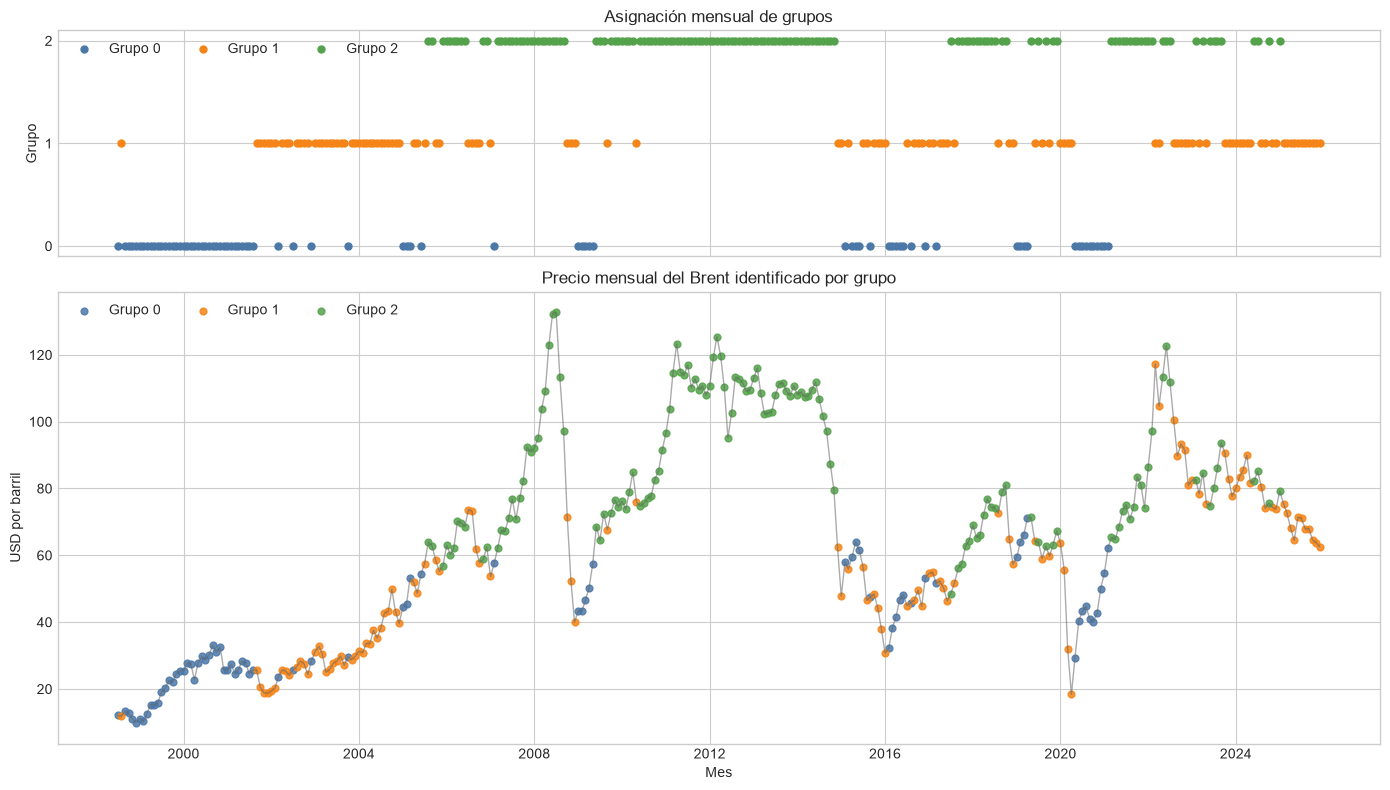

In [13]:
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True, gridspec_kw={"height_ratios": [1, 2]})

for cluster_id, color in enumerate(COLORS):
    subset = clustered[clustered["cluster"] == cluster_id]
    axes[0].scatter(subset["month"], subset["cluster"], s=25, color=color, label=f"Grupo {cluster_id}")
axes[0].set(
    title="Asignación mensual de grupos",
    ylabel="Grupo",
    yticks=range(FINAL_K),
)
axes[0].legend(ncol=3, loc="upper left")

axes[1].plot(clustered["month"], clustered["brent_price"], color="#666666", linewidth=1, alpha=0.55)
for cluster_id, color in enumerate(COLORS):
    subset = clustered[clustered["cluster"] == cluster_id]
    axes[1].scatter(subset["month"], subset["brent_price"], s=24, color=color, alpha=0.85, label=f"Grupo {cluster_id}")
axes[1].set(
    title="Precio mensual del Brent identificado por grupo",
    xlabel="Mes",
    ylabel="USD por barril",
)
axes[1].legend(ncol=3, loc="upper left")
plt.tight_layout()
plt.show()

In [14]:
clustered["next_cluster"] = clustered["cluster"].shift(-1)
transition_matrix = pd.crosstab(
    clustered["cluster"], clustered["next_cluster"], normalize="index",
).reindex(index=range(FINAL_K), columns=range(FINAL_K))
transition_matrix.index.name = "grupo actual"
transition_matrix.columns.name = "grupo siguiente"

changes = int(clustered["cluster"].ne(clustered["cluster"].shift()).sum() - 1)
print("Cambios de grupo entre meses consecutivos:", changes, "de", len(clustered) - 1)
display(transition_matrix.round(3))

Cambios de grupo entre meses consecutivos: 77 de 329


grupo siguiente,0,1,2
grupo actual,,,
0,0.756,0.192,0.051
1,0.159,0.681,0.159
2,0.000,0.159,0.841


El Grupo 2 es el más persistente: permanece en el mismo estado en el 84,1% de las transiciones observadas. En total se registran 77 cambios de grupo a lo largo de 329 transiciones mensuales. Esta persistencia es descriptiva y no representa una probabilidad predictiva validada.

### Comportamiento durante 2020-2022

La ventana 2020-2022 permite observar cómo se clasifican meses asociados con movimientos extraordinarios del mercado sin imponer de antemano una categoría específica para el período.

,meses_2020_2022,%_de_la_ventana
cluster,,
0,10,27.8
1,11,30.6
2,15,41.7


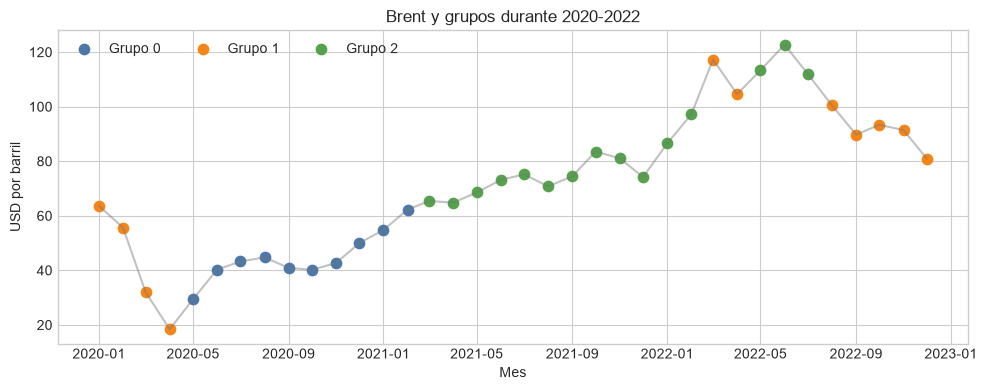

In [15]:
event_mask = clustered["month"].between("2020-01-01", "2022-12-01")
event_counts = clustered.loc[event_mask, "cluster"].value_counts().sort_index().reindex(range(FINAL_K), fill_value=0)
event_summary = pd.DataFrame({
    "meses_2020_2022": event_counts,
    "%_de_la_ventana": 100 * event_counts / event_counts.sum(),
})
display(event_summary.round(1))

fig, ax = plt.subplots(figsize=(10, 4))
event_data = clustered.loc[event_mask]
for cluster_id, color in enumerate(COLORS):
    subset = event_data[event_data["cluster"] == cluster_id]
    ax.scatter(subset["month"], subset["brent_price"], color=color, s=55, label=f"Grupo {cluster_id}")
ax.plot(event_data["month"], event_data["brent_price"], color="#777777", alpha=0.45)
ax.set(title="Brent y grupos durante 2020-2022", xlabel="Mes", ylabel="USD por barril")
ax.legend(ncol=3)
plt.tight_layout()
plt.show()

Los 36 meses se distribuyen entre los tres grupos: 10 en el Grupo 0, 11 en el Grupo 1 y 15 en el Grupo 2. La caída inicial de 2020, el rebote posterior y los precios elevados de 2021-2022 responden a perfiles diferentes; por lo tanto, el período no constituye un único régimen homogéneo.

## 11. Interpretación y relación con la investigación

Los experimentos supervisados previos evaluaron si GPR y las variables del mercado mejoraban la predicción del nivel o del retorno del Brent del mes siguiente. Sus resultados no mostraron una mejora robusta frente a referencias simples.

El clustering aborda una pregunta diferente. Los grupos resumen combinaciones contemporáneas recurrentes de precio, retorno, volatilidad, riesgo geopolítico y balance mundial. Así, el aprendizaje no supervisado aporta una lectura estructurada de la heterogeneidad histórica, aun cuando esa estructura no se traduzca en una señal predictiva estable.

La respuesta a la pregunta de investigación es, por tanto, matizada: se identifican tres perfiles interpretables, pero la separación estadística es débil y existe una transición gradual entre ellos. Los resultados no permiten afirmar causalidad ni anticipar automáticamente el comportamiento futuro del Brent.

### Controles de reproducibilidad

La celda siguiente verifica fechas, variables, dimensiones, métricas, estabilidad entre semillas y consistencia de la proyección PCA.

In [16]:
assert df["month"].is_monotonic_increasing and df["month"].is_unique
assert df["month"].equals(expected_months)
assert not set(FEATURES_FINAL).intersection(FUTURE_COLUMNS)
assert not analysis[FEATURES_FINAL].isna().any().any()
assert X_scaled.shape == (330, len(FEATURES_FINAL))
assert set(labels) == {0, 1, 2}
assert counts.sum() == len(analysis)
assert np.isclose(final_silhouette, 0.2008096781)
assert np.isclose(final_davies_bouldin, 1.6011654769)
assert np.allclose(seed_stability["ARI_vs_seed_42"], 1.0)
assert X_pca.shape == (330, 2)
assert np.isclose(pca.explained_variance_ratio_.sum(), 0.5524491383)

summary = {
    "periodo": [analysis["month"].min().strftime("%Y-%m"), analysis["month"].max().strftime("%Y-%m")],
    "observaciones": len(analysis),
    "features": FEATURES_FINAL,
    "k": FINAL_K,
    "silhouette": float(final_silhouette),
    "davies_bouldin": float(final_davies_bouldin),
    "pca_varianza_2d": float(pca.explained_variance_ratio_.sum()),
    "tamaños": {str(int(k)): int(v) for k, v in counts.items()},
    "cambios_temporales": changes,
    "meses_2020_2022": {str(int(k)): int(v) for k, v in event_counts.items()},
}
print("VALIDACIONES: OK")
print("RESULTADOS_RESUMEN")
print(json.dumps(summary, ensure_ascii=False, indent=2))

VALIDACIONES: OK
RESULTADOS_RESUMEN
{
  "periodo": [
    "1998-07",
    "2025-12"
  ],
  "observaciones": 330,
  "features": [
    "brent_price",
    "brent_return_pct",
    "brent_volatility_6m",
    "log_GPR",
    "world_market_balance"
  ],
  "k": 3,
  "silhouette": 0.20080967808861094,
  "davies_bouldin": 1.601165476928945,
  "pca_varianza_2d": 0.5524491382676338,
  "tamaños": {
    "0": 78,
    "1": 114,
    "2": 138
  },
  "cambios_temporales": 77,
  "meses_2020_2022": {
    "0": 10,
    "1": 11,
    "2": 15
  }
}


## 12. Conclusiones y limitaciones

K-Means con K=3 ofrece una síntesis interpretable de 330 meses del mercado Brent. Los perfiles diferencian condiciones de menor precio y recuperación volátil, meses de precio intermedio con retornos negativos y mayor GPR, y períodos de precio alto con menor volatilidad.

Sin embargo, el silhouette de 0,201, la ausencia de un codo pronunciado y la superposición en PCA muestran que el mercado se aproxima más a un continuo que a tres regímenes claramente separados. En consecuencia, el principal aporte del análisis es descriptivo: organiza patrones históricos y complementa los resultados predictivos, pero no demuestra capacidad de anticipación ni relaciones causales.

Las conclusiones deben interpretarse considerando las siguientes limitaciones:

- K-Means favorece grupos aproximadamente esféricos y utiliza distancia euclidiana.
- Los episodios extremos influyen en los centroides, aunque se conservan por su relevancia económica.
- La muestra mensual es relativamente pequeña y las series mundiales corresponden a datos históricos revisados.
- La asignación utiliza información contemporánea al cierre del mes; no constituye una predicción del período siguiente.
- La proyección PCA en dos dimensiones conserva el 55,24% de la varianza y no representa toda la geometría del espacio original.
- GPR interviene en la formación de los grupos, por lo que sus diferencias entre perfiles no son evidencia independiente de asociación con el Brent.